# 🟢 ark-beta-mini-v2 — Image-to-Text

## 🔴 Imports

In [19]:
from pathlib import Path
from datetime import datetime
from contextlib import redirect_stdout
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps, UnidentifiedImageError
import random
import json
import time
import sys
import math

## ⚙️ Configuration

In [ ]:
ROOT = Path.cwd()
if not (ROOT / "dataset").exists() and (ROOT / "ark-vision" / "dataset").exists():
    ROOT = ROOT / "ark-vision"

DATA = ROOT / "dataset" / "Alphabet_VISION_Dataset"
LOGS = ROOT / "logs"
LOGS.mkdir(parents=True, exist_ok=True)

# Explicit allowlist: only these dataset folders are loaded.
SELECTED_DATASETS = ["mnist_grayscale", "gender_face"]

# CNN batches require a common tensor size. Each image is aspect-fit into
# this canvas, then padded rather than stretched to distort its proportions.
IMAGE_WIDTH = 100
IMAGE_HEIGHT = 100
IMAGE_MODE = "L"  # Grayscale, one input channel

BATCH_SIZE = 8
EPOCHS = 10  # Additional epochs per run
LR = 1e-3
WEIGHT_DECAY = 0.0
EARLY_STOPPING_PATIENCE = 5
MIN_DELTA = 1e-4
OPTIMIZER_NAME = "Adam"
NUM_WORKERS = 0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(2)

CLASS_NAMES = [str(i) for i in range(10)] + ["male", "female"]
LABEL_TO_ID = {label: index for index, label in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

print(f"Dataset root: {DATA}")
print(f"Selected datasets: {SELECTED_DATASETS}")
print(f"Canvas: {IMAGE_WIDTH}x{IMAGE_HEIGHT}")
print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")
print(f"Device: {DEVICE}")

Dataset root: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset
Selected datasets: ['mnist', 'gender']
Canvas: 100x100
Classes (12): ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'male', 'female']
Device: cpu


## 🗂️ Dataset — Image/Text Pairs

In [21]:
IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"
}

def prepare_image(image: Image.Image) -> torch.Tensor:
    """Convert any supported image size to a fixed grayscale tensor.

    Aspect ratio is preserved: the image is thumbnail-fitted into the target
    canvas and centered on a black background. This avoids stretching images.
    """
    image = ImageOps.exif_transpose(image).convert(IMAGE_MODE)
    image.thumbnail((IMAGE_WIDTH, IMAGE_HEIGHT), Image.Resampling.LANCZOS)

    canvas = Image.new(IMAGE_MODE, (IMAGE_WIDTH, IMAGE_HEIGHT), color=0)
    left = (IMAGE_WIDTH - image.width) // 2
    top = (IMAGE_HEIGHT - image.height) // 2
    canvas.paste(image, (left, top))

    arr = np.asarray(canvas, dtype=np.float32).copy() / 255.0
    return torch.from_numpy(arr).unsqueeze(0)


class PairedDataset(Dataset):
    def __init__(self, split):
        self.items = []
        self.skipped = []

        split_root = DATA / split
        if not split_root.is_dir():
            raise FileNotFoundError(f"Split directory not found: {split_root}")

        for dataset_name in SELECTED_DATASETS:
            folder = split_root / dataset_name
            if not folder.is_dir():
                raise FileNotFoundError(
                    f"Selected dataset folder not found: {folder}"
                )

            for path in sorted(folder.rglob("*")):
                if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue

                caption_path = path.with_suffix(".txt")
                if not caption_path.is_file():
                    self.skipped.append((str(path), "missing .txt label"))
                    continue

                label = caption_path.read_text(encoding="utf-8-sig").strip().lower()
                if label not in LABEL_TO_ID:
                    self.skipped.append((str(path), f"unsupported label: {label!r}"))
                    continue

                self.items.append((path, LABEL_TO_ID[label]))

        if not self.items:
            raise ValueError(
                f"No labeled image/text pairs found for split={split!r}; "
                f"selected datasets={SELECTED_DATASETS}"
            )

        print(
            f"{split}: {len(self.items):,} labeled images; "
            f"{len(self.skipped):,} skipped"
        )
        if self.skipped:
            print("  First skipped examples:", self.skipped[:3])

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        path, label_id = self.items[index]
        try:
            with Image.open(path) as image:
                tensor = prepare_image(image)
        except (OSError, UnidentifiedImageError) as exc:
            raise RuntimeError(f"Could not read image: {path}") from exc

        return tensor, torch.tensor(label_id, dtype=torch.long)


# Quick sanity check: all labels should map to the 12 configured classes.
train_dataset = PairedDataset("train")
valid_dataset = PairedDataset("valid")
test_dataset = PairedDataset("test")

print("Class mapping:")
for name, class_id in LABEL_TO_ID.items():
    print(f"  {name:>6} -> {class_id}")

train: 1,120 labeled images; 0 skipped
valid: 280 labeled images; 0 skipped
test: 280 labeled images; 0 skipped
Class mapping:
       0 -> 0
       1 -> 1
       2 -> 2
       3 -> 3
       4 -> 4
       5 -> 5
       6 -> 6
       7 -> 7
       8 -> 8
       9 -> 9
    male -> 10
  female -> 11


## 🔄 DataLoaders

In [22]:
def loaders():
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    valid_loader = DataLoader(
        valid_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    return train_loader, valid_loader, test_loader


train_loader, valid_loader, test_loader = loaders()
print(f"Training batches:   {len(train_loader)}")
print(f"Validation batches: {len(valid_loader)}")
print(f"Test batches:       {len(test_loader)}")

sample_x, sample_y = next(iter(train_loader))
print("Batch image shape:", tuple(sample_x.shape))
print("Batch label shape:", tuple(sample_y.shape))
print("Batch labels:", [CLASS_NAMES[i] for i in sample_y[:8].tolist()])

Training batches:   140
Validation batches: 35
Test batches:       35
Batch image shape: (8, 1, 100, 100)
Batch label shape: (8,)
Batch labels: ['3', '8', '7', '3', '5', 'male', '5', '9']


## 💾 Checkpointing — Save and Resume

In [23]:
def optimizer_config(opt):
    return {
        "name": type(opt).__name__,
        "param_groups": [
            {
                "lr": group["lr"],
                "weight_decay": group.get("weight_decay", 0.0),
                "betas": group.get("betas"),
                "eps": group.get("eps"),
            }
            for group in opt.param_groups
        ],
    }


def model_signature(model):
    return {
        name: tuple(param.shape)
        for name, param in model.state_dict().items()
    }


def save_checkpoint(
    path, model, opt, epoch, best, history,
    training_start_time, elapsed_training_time,
    early_stopping_counter=0
):
    current_elapsed = elapsed_training_time + (time.time() - training_start_time)

    torch.save({
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": opt.state_dict(),
        "model_signature": model_signature(model),
        "optimizer_config": optimizer_config(opt),
        "epoch": epoch,
        "best_val_loss": best,
        "early_stopping_counter": early_stopping_counter,
        "history": history,
        "selected_datasets": SELECTED_DATASETS,
        "image_width": IMAGE_WIDTH,
        "image_height": IMAGE_HEIGHT,
        "class_names": CLASS_NAMES,
        "batch_size": BATCH_SIZE,
        "rng_state": torch.get_rng_state(),
        "numpy_rng_state": np.random.get_state(),
        "python_rng_state": random.getstate(),
        "elapsed_training_time": current_elapsed,
    }, path)

    hours, remainder = divmod(int(current_elapsed), 3600)
    minutes, seconds = divmod(remainder, 60)
    print(f"💾 Checkpoint saved: {path}")
    print(f"   Completed epochs: {epoch}")
    print(f"   Best validation loss: {best:.6f}")
    print(f"   Accumulated training time: {hours:02d}:{minutes:02d}:{seconds:02d}")


def resume(path, model, opt):
    print("=" * 60)
    print("🔍 Checking for an existing checkpoint...")
    print(f"Checkpoint path: {path}")

    if not path.is_file():
        print("🆕 No checkpoint found; starting from scratch.")
        print("=" * 60)
        return 0, float("inf"), [], 0.0, 0

    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)

    expected_config = {
        "selected_datasets": SELECTED_DATASETS,
        "image_width": IMAGE_WIDTH,
        "image_height": IMAGE_HEIGHT,
        "class_names": CLASS_NAMES,
        "batch_size": BATCH_SIZE,
    }
    for key, expected in expected_config.items():
        if checkpoint.get(key) != expected:
            raise ValueError(
                f"Checkpoint configuration mismatch for {key!r}. "
                f"Saved={checkpoint.get(key)!r}; current={expected!r}"
            )

    if checkpoint.get("model_signature") != model_signature(model):
        raise ValueError("Model architecture differs from the checkpoint.")

    if checkpoint.get("optimizer_config") != optimizer_config(opt):
        raise ValueError(
            "Optimizer settings differ from the checkpoint. "
            "Use matching settings or start a new run."
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    opt.load_state_dict(checkpoint["optimizer_state_dict"])
    torch.set_rng_state(checkpoint["rng_state"])
    np.random.set_state(checkpoint["numpy_rng_state"])
    random.setstate(checkpoint["python_rng_state"])

    elapsed = checkpoint.get("elapsed_training_time", 0.0)
    hours, remainder = divmod(int(elapsed), 3600)
    minutes, seconds = divmod(remainder, 60)

    print("✅ Checkpoint loaded.")
    print(f"Last completed epoch: {checkpoint['epoch']}")
    print(f"Best validation loss: {checkpoint['best_val_loss']:.6f}")
    print(f"Recorded history rows: {len(checkpoint['history'])}")
    print(f"Previous training time: {hours:02d}:{minutes:02d}:{seconds:02d}")
    print("=" * 60)

    return (
        checkpoint["epoch"],
        checkpoint["best_val_loss"],
        checkpoint["history"],
        elapsed,
        checkpoint.get("early_stopping_counter", 0),
    )

## 🧠 Model Architecture — BetaMini CNN

In [24]:
class BetaMini(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Makes the classifier independent of the original image dimensions.
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 4 * 4, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.1),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = BetaMini().to(DEVICE)
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 60)
print("🚀 Model: ARK Beta Mini v2")
print(f"🧠 Initialized on: {DEVICE}")
print(f"🔢 Trainable parameters: {trainable_params:,}")
print(f"🖼️ Input tensor: 1 x {IMAGE_HEIGHT} x {IMAGE_WIDTH}")
print(f"🎯 Output classes ({NUM_CLASSES}): {CLASS_NAMES}")
print("🏗️ Architecture: CNN + Adaptive Average Pooling")
print("✅ Model initialization completed.")
print("=" * 60)

🚀 Model: ARK Beta Mini v2
🧠 Initialized on: cpu
🔢 Trainable parameters: 39,500
🖼️ Input tensor: 1 x 100 x 100
🎯 Output classes (12): ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'male', 'female']
🏗️ Architecture: CNN + Adaptive Average Pooling
✅ Model initialization completed.


## 🏋️ Training and Validation

In [25]:
MODEL_NAME = "ark-beta-mini-v2"
MODEL_LOGS = ROOT / "logs" / MODEL_NAME
MODEL_LOGS.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
RUN_DIR = MODEL_LOGS / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

CHECKPOINT_DIR = RUN_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_PATH = CHECKPOINT_DIR / "best.pt"
LOG_PATH = RUN_DIR / "training.log"
HISTORY_PATH = RUN_DIR / "history.json"
PLOT_PATH = RUN_DIR / "training_plot.png"

previous_checkpoints = sorted(
    MODEL_LOGS.glob("*/checkpoints/best.pt"),
    key=lambda p: p.stat().st_mtime,
)
previous_checkpoint = previous_checkpoints[-1] if previous_checkpoints else None
resume_path = previous_checkpoint if previous_checkpoint else BEST_PATH

class Tee:
    def __init__(self, *streams):
        self.streams = streams

    def write(self, message):
        for stream in self.streams:
            stream.write(message)
            stream.flush()

    def flush(self):
        for stream in self.streams:
            stream.flush()


with open(LOG_PATH, "a", encoding="utf-8") as log_file:
    with redirect_stdout(Tee(sys.stdout, log_file)):
        print("=" * 70)
        print(f"🚀 Model: {MODEL_NAME}")
        print(f"📅 Run ID: {RUN_ID}")
        print(f"📁 Run directory: {RUN_DIR}")
        print(f"🖥️ Device: {DEVICE}")
        print(f"🔢 Requested additional epochs: {EPOCHS}")
        print(f"📚 Selected datasets: {SELECTED_DATASETS}")
        print("=" * 70)

        model = BetaMini().to(DEVICE)
        if OPTIMIZER_NAME != "Adam":
            raise ValueError(f"Unsupported optimizer: {OPTIMIZER_NAME}")
        optimizer = torch.optim.Adam(
            model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
        )

        start_epoch, best, history, elapsed_training_time, early_stopping_counter = resume(
            resume_path, model, optimizer
        )
        training_start_time = time.time()

        print(f"Training batches: {len(train_loader)}")
        print(f"Validation batches: {len(valid_loader)}")
        print("\n🏋️ Starting training...")

        for epoch in range(start_epoch, start_epoch + EPOCHS):
            model.train()
            train_loss_sum = 0.0
            train_count = 0

            for x, y in train_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                logits = model(x)
                loss = nn.functional.cross_entropy(logits, y)
                loss.backward()
                optimizer.step()

                train_loss_sum += loss.item() * y.size(0)
                train_count += y.size(0)

            if train_count == 0:
                raise ValueError("Training dataset is empty.")

            model.eval()
            valid_loss_sum = 0.0
            valid_correct = 0
            valid_count = 0

            with torch.no_grad():
                for x, y in valid_loader:
                    x, y = x.to(DEVICE), y.to(DEVICE)
                    logits = model(x)
                    valid_loss_sum += nn.functional.cross_entropy(
                        logits, y, reduction="sum"
                    ).item()
                    valid_correct += (logits.argmax(dim=1) == y).sum().item()
                    valid_count += y.size(0)

            if valid_count == 0:
                raise ValueError("Validation dataset is empty.")

            train_loss = train_loss_sum / train_count
            val_loss = valid_loss_sum / valid_count
            val_accuracy = valid_correct / valid_count
            improved_enough = val_loss < best - MIN_DELTA

            row = {
                "epoch": epoch + 1,
                "train_loss": train_loss,
                "valid_loss": val_loss,
                "valid_accuracy": val_accuracy,
            }
            history.append(row)

            if val_loss < best:
                best = val_loss
                save_checkpoint(
                    BEST_PATH, model, optimizer, epoch + 1, best, history,
                    training_start_time, elapsed_training_time,
                    early_stopping_counter,
                )

            if improved_enough:
                early_stopping_counter = 0
            else:
                early_stopping_counter += 1

            # Save the latest counter/history in the best checkpoint when possible.
            with open(HISTORY_PATH, "w", encoding="utf-8") as f:
                json.dump(history, f, ensure_ascii=False, indent=2)

            print(
                f"Epoch {epoch + 1}: "
                f"train_loss={train_loss:.4f}, "
                f"valid_loss={val_loss:.4f}, "
                f"valid_accuracy={val_accuracy:.2%}, "
                f"early_stopping={early_stopping_counter}/{EARLY_STOPPING_PATIENCE}"
            )

            epochs_seen = [r["epoch"] for r in history]
            train_losses = [r["train_loss"] for r in history]
            valid_losses = [r["valid_loss"] for r in history]
            accuracies = [r["valid_accuracy"] * 100 for r in history]

            fig, axes = plt.subplots(1, 2, figsize=(12, 4))
            axes[0].plot(epochs_seen, train_losses, label="Train Loss")
            axes[0].plot(epochs_seen, valid_losses, label="Validation Loss")
            axes[0].set_title("Training and Validation Loss")
            axes[0].set_xlabel("Epoch")
            axes[0].set_ylabel("Loss")
            axes[0].legend()
            axes[0].grid(True)

            axes[1].plot(epochs_seen, accuracies, label="Validation Accuracy")
            axes[1].set_title("Validation Accuracy")
            axes[1].set_xlabel("Epoch")
            axes[1].set_ylabel("Accuracy (%)")
            axes[1].legend()
            axes[1].grid(True)

            fig.tight_layout()
            fig.savefig(PLOT_PATH, dpi=150)
            plt.close(fig)

            if early_stopping_counter >= EARLY_STOPPING_PATIENCE:
                print(
                    f"🛑 Early stopping at epoch {epoch + 1}: "
                    f"no sufficient validation improvement for "
                    f"{EARLY_STOPPING_PATIENCE} consecutive epochs."
                )
                break

        total_training_time = elapsed_training_time + (time.time() - training_start_time)
        hours, remainder = divmod(int(total_training_time), 3600)
        minutes, seconds = divmod(remainder, 60)

        print("\n" + "=" * 70)
        print("✅ Training run completed.")
        print(f"🏆 Best checkpoint: {BEST_PATH}")
        print(f"📄 Training log: {LOG_PATH}")
        print(f"📊 History: {HISTORY_PATH}")
        print(f"📈 Plot: {PLOT_PATH}")
        print(f"🏆 Best validation loss: {best:.6f}")
        print(f"⏱️ Accumulated training time: {hours:02d}:{minutes:02d}:{seconds:02d}")
        print("=" * 70)

🚀 Model: ark-beta-mini-v2
📅 Run ID: 2026-10-21_14-38-59
📁 Run directory: F:\pyvenv\ARK\ark-imagine\logs\ark-beta-mini-v2\2026-10-21_14-38-59
🖥️ Device: cpu
🔢 Requested additional epochs: 10
📚 Selected datasets: ['mnist', 'gender']
🔍 Checking for an existing checkpoint...
Checkpoint path: F:\pyvenv\ARK\ark-imagine\logs\ark-beta-mini-v2\2026-10-21_14-34-27\checkpoints\best.pt
✅ Checkpoint loaded.
Last completed epoch: 18
Best validation loss: 0.554573
Recorded history rows: 18
Previous training time: 00:03:40
Training batches: 140
Validation batches: 35

🏋️ Starting training...
Epoch 19: train_loss=0.5498, valid_loss=0.5698, valid_accuracy=75.71%, early_stopping=1/5
Epoch 20: train_loss=0.5367, valid_loss=0.5724, valid_accuracy=77.50%, early_stopping=2/5
💾 Checkpoint saved: F:\pyvenv\ARK\ark-imagine\logs\ark-beta-mini-v2\2026-10-21_14-38-59\checkpoints\best.pt
   Completed epochs: 21
   Best validation loss: 0.534139
   Accumulated training time: 00:04:07
Epoch 21: train_loss=0.4887, val

## 🔴 Test

In [26]:
# Prefer this run's best checkpoint; otherwise use the latest previous best.
available_checkpoints = sorted(
    MODEL_LOGS.glob("*/checkpoints/best.pt"),
    key=lambda p: p.stat().st_mtime,
)
if BEST_PATH.is_file():
    EVAL_PATH = BEST_PATH
elif available_checkpoints:
    EVAL_PATH = available_checkpoints[-1]
else:
    raise FileNotFoundError("No best.pt checkpoint found. Train the model first.")

print(f"🏆 Evaluation checkpoint: {EVAL_PATH}")
checkpoint = torch.load(EVAL_PATH, map_location=DEVICE, weights_only=False)

if checkpoint.get("class_names") != CLASS_NAMES:
    raise ValueError("Checkpoint class mapping does not match current CLASS_NAMES.")

model = BetaMini().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_loss_sum = 0.0
test_correct = 0
test_total = 0
class_correct = [0] * NUM_CLASSES
class_total = [0] * NUM_CLASSES

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        test_loss_sum += nn.functional.cross_entropy(
            logits, y, reduction="sum"
        ).item()
        predictions = logits.argmax(dim=1)
        test_correct += (predictions == y).sum().item()
        test_total += y.size(0)

        for target, prediction in zip(y.cpu().tolist(), predictions.cpu().tolist()):
            class_total[target] += 1
            if target == prediction:
                class_correct[target] += 1

if test_total == 0:
    raise ValueError("Test dataset is empty.")

test_loss = test_loss_sum / test_total
test_accuracy = test_correct / test_total

print("\n" + "=" * 60)
print("🏆 Final Test Results")
print(f"Test samples: {test_total:,}")
print(f"Test loss: {test_loss:.6f}")
print(f"Test accuracy: {test_accuracy:.2%}")
print("\nPer-class accuracy:")
for class_id, class_name in enumerate(CLASS_NAMES):
    if class_total[class_id]:
        acc = class_correct[class_id] / class_total[class_id]
        print(f"  {class_name:>6}: {acc:.2%} ({class_correct[class_id]}/{class_total[class_id]})")
    else:
        print(f"  {class_name:>6}: no test samples")
print("=" * 60)

🏆 Evaluation checkpoint: F:\pyvenv\ARK\ark-imagine\logs\ark-beta-mini-v2\2026-10-21_14-38-59\checkpoints\best.pt

🏆 Final Test Results
Test samples: 280
Test loss: 0.555465
Test accuracy: 78.93%

Per-class accuracy:
       0: 85.00% (17/20)
       1: 100.00% (20/20)
       2: 80.00% (16/20)
       3: 65.00% (13/20)
       4: 80.00% (16/20)
       5: 85.00% (17/20)
       6: 85.00% (17/20)
       7: 90.00% (18/20)
       8: 70.00% (14/20)
       9: 70.00% (14/20)
    male: 97.50% (39/40)
  female: 50.00% (20/40)


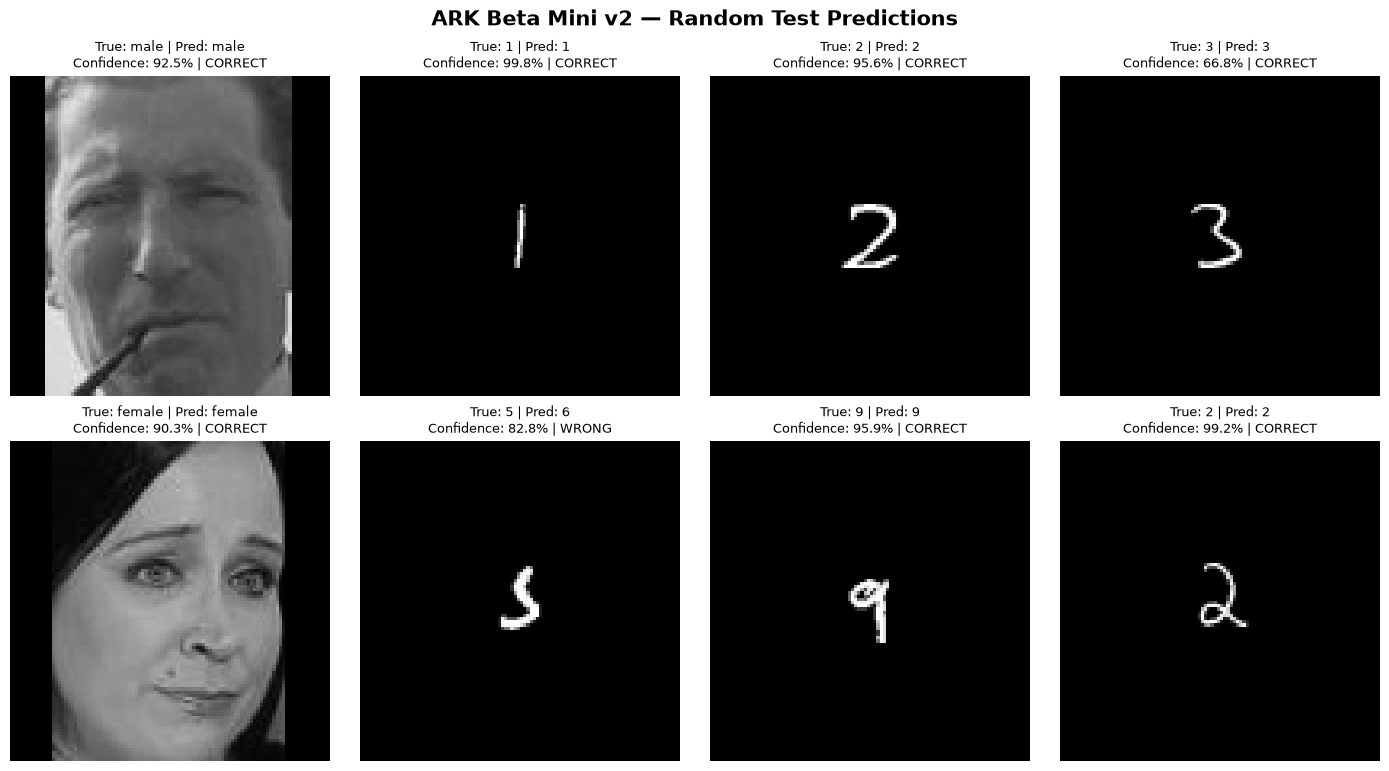


🔍 Random Test Sample Results
--------------------------------------------------------------------------------
01. True=male | Predicted=male | Confidence=92.53% | ✅ CORRECT
    Image: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset\test\gender\male_11.jpg
02. True=1 | Predicted=1 | Confidence=99.76% | ✅ CORRECT
    Image: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset\test\mnist\1_2.png
03. True=2 | Predicted=2 | Confidence=95.64% | ✅ CORRECT
    Image: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset\test\mnist\2_20.png
04. True=3 | Predicted=3 | Confidence=66.83% | ✅ CORRECT
    Image: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset\test\mnist\3_5.png
05. True=female | Predicted=female | Confidence=90.27% | ✅ CORRECT
    Image: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset\test\gender\female_3.jpg
06. True=5 | Predicted=6 | Confidence=82.78% | ❌ WRONG
    Image: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset\test\mnist\5

In [30]:
# Randomly inspect a few test predictions.
NUM_TEST_IMAGES = 8
RANDOM_SEED = None  # Set to 42 for repeatable selections

rng = random.Random(RANDOM_SEED)
num_samples = min(NUM_TEST_IMAGES, len(test_dataset))
selected_indices = rng.sample(range(len(test_dataset)), num_samples)

images = []
true_ids = []
image_paths = []

for index in selected_indices:
    image_tensor, label_tensor = test_dataset[index]
    images.append(image_tensor)
    true_ids.append(label_tensor.item())
    image_paths.append(str(test_dataset.items[index][0]))

x_batch = torch.stack(images).to(DEVICE)
with torch.no_grad():
    logits = model(x_batch)
    probabilities = torch.softmax(logits, dim=1)
    confidences, predicted_ids = probabilities.max(dim=1)

predicted_ids = predicted_ids.cpu().tolist()
confidences = confidences.cpu().tolist()
images_np = x_batch.cpu().numpy()[:, 0]

cols = 4
rows = math.ceil(num_samples / cols)
fig, axes = plt.subplots(
    rows, cols, figsize=(14, 3.8 * rows), squeeze=False,
    layout="constrained"
)

for i, ax in enumerate(axes.flat):
    if i >= num_samples:
        ax.axis("off")
        continue

    true_name = CLASS_NAMES[true_ids[i]]
    predicted_name = CLASS_NAMES[predicted_ids[i]]
    status = "CORRECT" if predicted_ids[i] == true_ids[i] else "WRONG"

    ax.imshow(images_np[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"True: {true_name} | Pred: {predicted_name}\n"
        f"Confidence: {confidences[i]:.1%} | {status}",
        fontsize=9,
    )
    ax.axis("off")

fig.suptitle("ARK Beta Mini v2 — Random Test Predictions", fontsize=15, fontweight="bold")
plt.show()

print("\n" + "=" * 80)
print("🔍 Random Test Sample Results")
print("-" * 80)
for i in range(num_samples):
    status = "✅ CORRECT" if predicted_ids[i] == true_ids[i] else "❌ WRONG"
    print(
        f"{i + 1:02d}. True={CLASS_NAMES[true_ids[i]]} | "
        f"Predicted={CLASS_NAMES[predicted_ids[i]]} | "
        f"Confidence={confidences[i]:.2%} | {status}"
    )
    print(f"    Image: {image_paths[i]}")
print("-" * 80)
print(f"Random sample count: {num_samples}")
print(f"Full test accuracy: {test_accuracy:.2%}")
print("=" * 80)